# 03 Model experiments
Reads the experiment log written by `python -m src.models.train` (every run is logged, nothing typed by hand).

In [1]:
import sys
import pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.utils.config import load_config, rpath
cfg = load_config()
import json

In [2]:
log = pd.read_csv(ROOT/'reports'/'experiment_log.csv')
log[log.task=='churn'].pivot(index='model', columns='split', values='roc_auc').sort_values('test', ascending=False).round(4)

split,test,val
model,,
logistic_regression,0.7901,0.8012
random_forest,0.7896,0.8075
ann,0.7869,0.8042
xgboost,0.7860,0.8113
knn,0.7781,0.7901
lightgbm,0.7774,0.8008
decision_tree,0.7525,0.7769
lstm,0.7395,0.7626


In [3]:
pd.read_csv(ROOT/'reports'/'model_comparison.csv').round(3)

,model,val_roc_auc,test_roc_auc,test_recall,test_precision,test_f1,test_accuracy,test_tn,test_fp,test_fn,test_tp,val_recall
0,xgboost,0.811,0.786,0.765,0.765,0.765,0.734,237,105,105,341,0.778
1,random_forest,0.808,0.790,0.783,0.760,0.771,0.737,232,110,97,349,0.812
2,ann,0.804,0.787,0.758,0.763,0.760,0.730,237,105,108,338,0.769
3,logistic_regression,0.801,0.790,0.767,0.758,0.763,0.730,233,109,104,342,0.769
4,lightgbm,0.801,0.777,0.760,0.745,0.752,0.717,226,116,107,339,0.780
5,knn,0.790,0.778,0.785,0.737,0.760,0.720,217,125,96,350,0.821
6,decision_tree,0.777,0.753,0.783,0.743,0.762,0.723,221,121,97,349,0.809
7,lstm,0.763,0.740,0.724,0.726,0.725,0.689,220,122,123,323,0.767


In [4]:
meta = json.loads((ROOT/'models_artifacts'/'metadata.json').read_text())
print('production:', meta['production_churn_model'], '| best on validation:', meta['best_model_by_val_auc_overall'])
print('targets met:', meta['targets_met'])
log[log.task=='clv'].round(3)[['model','split','r2','mae','params']]

production: xgboost | best on validation: xgboost
targets met: {'churn_auc': False, 'churn_recall': True, 'clv_r2': False}


,model,split,r2,mae,params
43,ridge,val,0.770,446.546,"{'reg__alpha': 100.0, 'cv_mean': 0.3378, 'cv_s..."
44,ridge,test,0.415,422.199,"{'reg__alpha': 100.0, 'cv_mean': 0.3378, 'cv_s..."
45,random_forest_reg,val,0.234,476.774,"{'n_estimators': 400, 'min_samples_leaf': 3, '..."
46,random_forest_reg,test,0.463,396.293,"{'n_estimators': 400, 'min_samples_leaf': 3, '..."
47,xgboost_reg,val,0.118,493.076,"{'subsample': 0.9, 'max_depth': 3, 'learning_r..."
48,xgboost_reg,test,0.406,416.018,"{'subsample': 0.9, 'max_depth': 3, 'learning_r..."


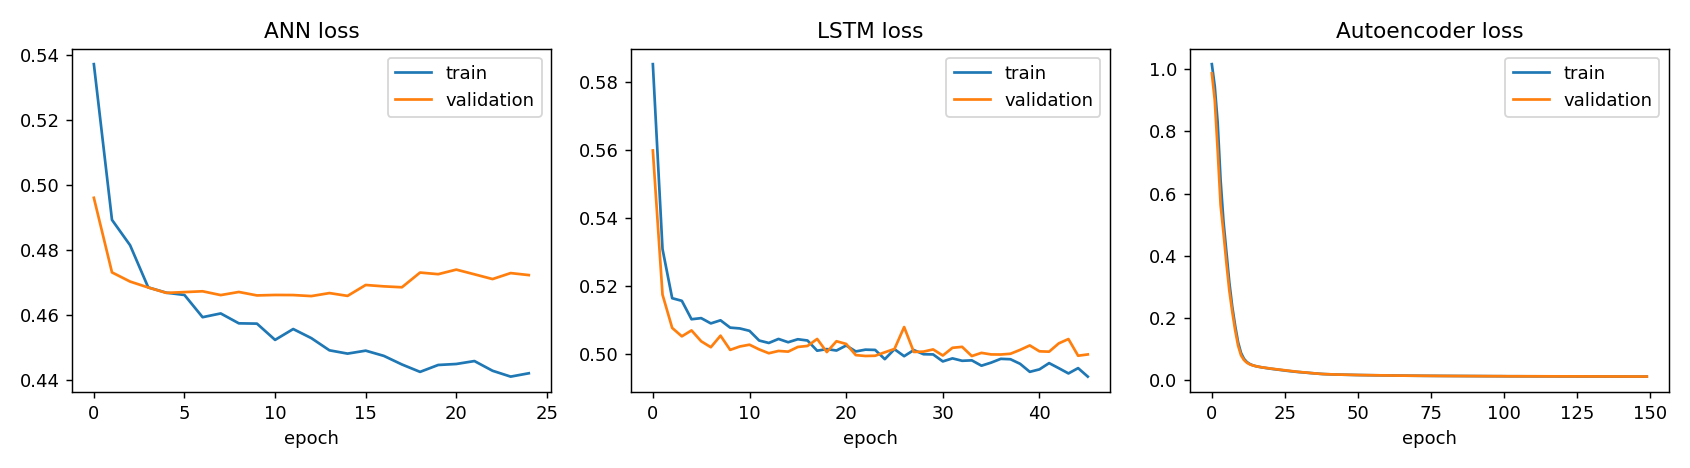

In [5]:
from IPython.display import Image
Image(str(ROOT/'reports'/'loss_curves.png'))